# Analyse des ventes avec Pandas

## 1. Importation des bibliothèques et chargement du dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('dataset_ventes_analyse_pandas.csv')

## 2. Exploration des données

In [3]:
print("Les 10 premières lignes du DataFrame :")
print(df.head(10))

print("Le nb de ligne et de colonnes du DataFrame :")
print(df.shape)

print("Le type de données de chaque colonne du DataFrame :")
print(df.info())

print("Le résumé statistique du DataFrame :")
print(df.describe())

print("Les valeurs manquantes du DataFrame :")
print(df.isna().sum())

print("Les doublons: ")
print(df.duplicated().sum())

Les 10 premières lignes du DataFrame :
   Order_ID        Date Customer_ID Gender   Age         City      Product  \
0  CMD00374  2025-10-24     CLT0255  Femme  48.0        Thiès   Ordinateur   
1  CMD00984  2025-08-24     CLT0001  Homme  39.0      Kaolack          Sac   
2  CMD00377  2025-07-20     CLT0051  Femme  27.0  Saint-Louis          Sac   
3  CMD00910  2025-04-14     CLT0347  Femme  54.0  Saint-Louis    Téléphone   
4  CMD00821  2025-04-21     CLT0277  Femme  61.0     Rufisque    Téléphone   
5  CMD00522  2025-09-28     CLT0028  Homme  26.0        Dakar    Écouteurs   
6  CMD00358  2025-10-10     CLT0002  Homme  56.0     Rufisque  Ventilateur   
7  CMD00345  2025-03-26     CLT0061  Femme  26.0  Saint-Louis  Ventilateur   
8  CMD00730  2025-12-14     CLT0111  Homme  49.0        Dakar          Sac   
9  CMD00722  2025-07-15     CLT0112  Homme  65.0        Dakar  Ventilateur   

       Category  Quantity  Unit_Price  Total_Sales  Payment_Method  \
0  Informatique         4    298

## 3. Nettoyage des données

In [4]:
#Doublons
print("SUPPRIMONSONS LES DOUBLONS")
df = df.drop_duplicates()

SUPPRIMONSONS LES DOUBLONS


In [5]:
#Valeurs manquantes
print("Traitons les valeurs manquantes")
df['Gender'] = df["Gender"].fillna(df["Gender"].mode()[0])
df['City'] = df["City"].fillna(df["City"].mode()[0])
df['Satisfaction'] = df["Satisfaction"].fillna(df["Satisfaction"].median())

Traitons les valeurs manquantes


In [6]:
#Normalisation du texte
print("Corrigeons les noms des villes")
df["City"] = df["City"].str.strip().str.lower()
df["City"] = df["City"].str.title()
df["City"] = df["City"].replace({"Thies": "Thiès"})

df["Payment_Method"] = df["Payment_Method"].str.strip().str.lower().str.title()
df["Payment_Method"] = df["Payment_Method"].replace({"Especes": "Espèces"})
df['Product'] = df["Product"].str.strip().str.lower().str.title()

Corrigeons les noms des villes


In [7]:
#Dates
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

In [8]:
#Prix anormaux et manquants
print("Nombre de prix anormaux :", (df["Unit_Price"] <= 0).sum())
print("Nombre de prix manquants :", df["Unit_Price"].isna().sum())
mediane_prix = df.loc[df["Unit_Price"] > 0, "Unit_Price"].median()
df.loc[df["Unit_Price"] <= 0, "Unit_Price"] = mediane_prix
df["Unit_Price"] = df["Unit_Price"].fillna(mediane_prix)

Nombre de prix anormaux : 4
Nombre de prix manquants : 10


In [9]:
#Ventes incoherentes
df_incoherent = df[
    ~np.isclose(df["Total_Sales"], df["Quantity"] * df["Unit_Price"])
]
print("Nombre de ventes incohérentes :", len(df_incoherent))

Nombre de ventes incohérentes : 353


In [10]:
#Quantites anormales
print("Nombre de quantités anormales :", (df["Quantity"] <= 0).sum())
mediane_quantite = df.loc[df["Quantity"] > 0, "Quantity"].median()
df.loc[df["Quantity"] <= 0, "Quantity"] = mediane_quantite

df["Total_Sales"] = df["Quantity"] * df["Unit_Price"]

Nombre de quantités anormales : 4


In [11]:
#Ages anormaux
condition = (df["Age"] < 18) | (df["Age"] > 90)
print("Les âges anormaux :", condition.sum())
df.loc[condition, "Age"] = np.nan
print("Âges manquants :", df["Age"].isna().sum())
df["Age"] = df["Age"].fillna(df["Age"].median())

Les âges anormaux : 5
Âges manquants : 29


## 4. Analyse statistique

In [12]:
print("Etudions l'age des clients :")
print("Age moyen :", df["Age"].mean())
print("Age median :", df["Age"].median())
print("Age min :", df["Age"].min())
print("Age max :", df["Age"].max())
print("ecart type :", df["Age"].std())

Etudions l'age des clients :
Age moyen : 41.43833333333333
Age median : 41.0
Age min : 18.0
Age max : 65.0
ecart type : 13.363008851309987


In [13]:
print("Etudions les quantités vendues :")
print("Quantité moyenne :", df["Quantity"].mean())
print("Quantité mediane :", df["Quantity"].median())
print("Quantité min :", df["Quantity"].min())
print("Quantité max :", df["Quantity"].max())
print("ecart type :", df["Quantity"].std())

Etudions les quantités vendues :
Quantité moyenne : 2.9941666666666666
Quantité mediane : 3.0
Quantité min : 1
Quantité max : 5
ecart type : 1.4203804206403077


In [14]:
print("Etudions les prix unitaires :")
print("Prix unitaire moyen :", df["Unit_Price"].mean())
print("Prix unitaire median :", df["Unit_Price"].median())
print("Prix unitaire min :", df["Unit_Price"].min())
print("Prix unitaire max :", df["Unit_Price"].max())
print("ecart type :", df["Unit_Price"].std())

Etudions les prix unitaires :
Prix unitaire moyen : 69667.69
Prix unitaire median : 32625.5
Prix unitaire min : 16256.0
Prix unitaire max : 357753.0
ecart type : 92934.15248608144


In [15]:
print("Etudions les ventes totales :")
print("Ventes totales moyennes :", df["Total_Sales"].mean())
print("Ventes totales medianes :", df["Total_Sales"].median())
print("Ventes totales min :", df["Total_Sales"].min())
print("Ventes totales max :", df["Total_Sales"].max())
print("Somme des ventes totales :", df["Total_Sales"].sum())
print("ecart type :", df["Total_Sales"].std())

Etudions les ventes totales :
Ventes totales moyennes : 207838.43375
Ventes totales medianes : 95718.0
Ventes totales min : 16286.0
Ventes totales max : 1788765.0
Somme des ventes totales : 249406120.5
ecart type : 323940.4970362942


In [16]:
print("Etudions la satisfaction des clients :")
print("Satisfaction moyenne :", df["Satisfaction"].mean())
print("Satisfaction mediane :", df["Satisfaction"].median())
print("Satisfaction min :", df["Satisfaction"].min())
print("Satisfaction max :", df["Satisfaction"].max())

Etudions la satisfaction des clients :
Satisfaction moyenne : 3.7775
Satisfaction mediane : 4.0
Satisfaction min : 1.0
Satisfaction max : 5.0


## 5. Visualisation

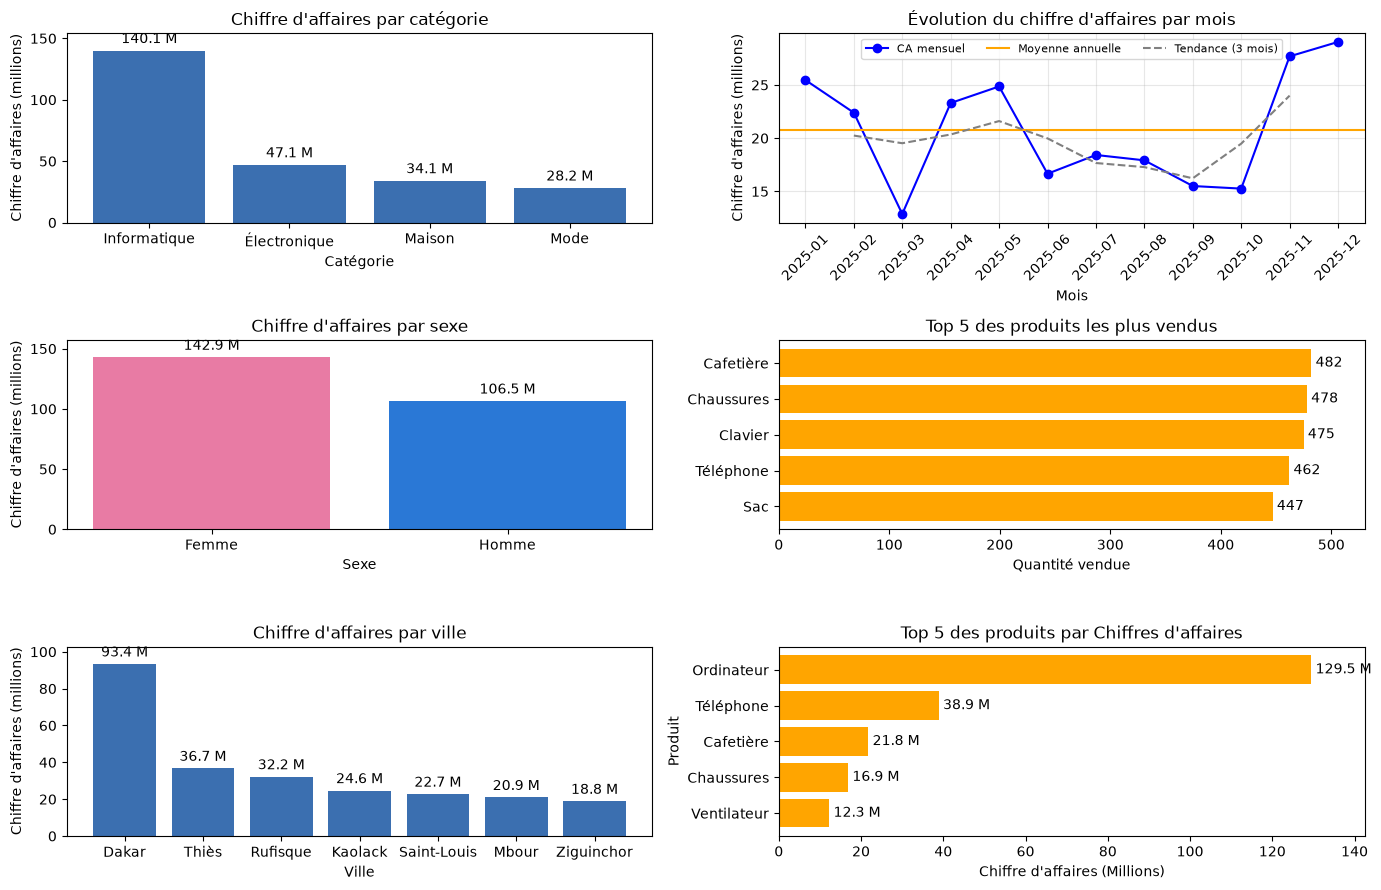

In [17]:
fig, axes = plt.subplots(3, 2, figsize=(14, 9))

#Chiffre d'affaires par catégorie
ventes_categorie = df.groupby("Category")["Total_Sales"].sum().sort_values(ascending=False)
barres = axes[0,0].bar(ventes_categorie.index, ventes_categorie.values / 1_000_000, color="#3b6fb0")
axes[0,0].bar_label(barres, fmt="%.1f M", padding=3)
axes[0,0].margins(y=0.1)
axes[0,0].set_title("Chiffre d'affaires par catégorie")
axes[0,0].set_xlabel("Catégorie")
axes[0,0].set_ylabel("Chiffre d'affaires (millions)")

#Évolution mensuelle
ventes_mensuelles = df.groupby(df["Date"].dt.to_period("M"))["Total_Sales"].sum()
mois = ventes_mensuelles.index.astype(str)
ca_mois = ventes_mensuelles.values / 1_000_000
axes[0,1].plot(mois, ca_mois, marker="o", color="blue", label="CA mensuel")
axes[0,1].axhline(ca_mois.mean(), color="orange", label="Moyenne annuelle")
moyenne_mobile = ventes_mensuelles.rolling(3, center=True).mean() / 1_000_000
axes[0,1].plot(mois, moyenne_mobile, linestyle="--", color="grey", label="Tendance (3 mois)")
axes[0,1].legend(loc="upper center", ncol=3, fontsize=8)
axes[0,1].set_title("Évolution du chiffre d'affaires par mois")
axes[0,1].set_xlabel("Mois")
axes[0,1].set_ylabel("Chiffre d'affaires (millions)")
axes[0,1].tick_params(axis="x", rotation=45)
axes[0,1].grid(alpha=0.3)

#Chiffre d'affaires par sexe
ventes_sexe = df.groupby("Gender")["Total_Sales"].sum()
barres = axes[1,0].bar(ventes_sexe.index, ventes_sexe.values / 1_000_000, color=["#e87ba4", "#2a78d6"])
axes[1,0].bar_label(barres, fmt="%.1f M", padding=3)
axes[1,0].margins(y=0.1)
axes[1,0].set_title("Chiffre d'affaires par sexe")
axes[1,0].set_xlabel("Sexe")
axes[1,0].set_ylabel("Chiffre d'affaires (millions)")


#Top 5 des produits
produits_vendus = df.groupby("Product")["Quantity"].sum().nlargest(5).sort_values()
barres = axes[1,1].barh(produits_vendus.index, produits_vendus.values, color="orange")
axes[1,1].bar_label(barres, padding=3)
axes[1,1].margins(x=0.1)
axes[1,1].set_title("Top 5 des produits les plus vendus")
axes[1,1].set_xlabel("Quantité vendue")
#axes[1,1].set_ylabel("")

#Chiffre d'affaires par ville
vente_villes=df.groupby("City")["Total_Sales"].sum().sort_values(ascending=False)
barres= axes[2,0].bar(vente_villes.index,vente_villes.values / 1_000_000, color="#3b6fb0")
axes[2,0].bar_label(barres,fmt="%.1f M", padding=3)
axes[2,0].margins(y=0.1)
axes[2,0].set_title("Chiffre d'affaires par ville")
axes[2,0].set_xlabel("Ville")
axes[2,0].set_ylabel("Chiffre d'affaires (millions)")


#Top5 des chiffres d'affaires
chiffre_affaire = df.groupby("Product")["Total_Sales"].sum().nlargest(5).sort_values()
barres = axes[2,1].barh(chiffre_affaire.index, chiffre_affaire.values / 1_000_000, color="orange")
axes[2,1].bar_label(barres,fmt="%.1f M" ,padding=3)
axes[2,1].margins(x=0.1)
axes[2,1].set_title("Top 5 des produits par Chiffres d'affaires")
axes[2,1].set_xlabel("Chiffre d'affaires (Millions)")
axes[2,1].set_ylabel("Produit")



plt.tight_layout()

## 6. Exportation et conclusion

In [18]:
#Export du dataset nettoyé et des graphiques
df.to_csv('dataset_ventes_analyse_pandas_cleaned.csv', index=False)
fig.savefig('graphiques_ventes.png', dpi=150)

In [19]:
#Interprétation des résultats
ca_total = df["Total_Sales"].sum()
paiement=df["Payment_Method"].value_counts()
print("CONCLUSION")
print("Chiffre d'affaires total :", ca_total)
print("Catégorie la plus rentable :", ventes_categorie.idxmax(),
      "(", round(ventes_categorie.max() / ca_total * 100, 1), "% du CA )")
print("Meilleur mois :", ventes_mensuelles.idxmax())
print("Mois le plus faible :", ventes_mensuelles.idxmin())
print("Moyen de paiement le plus utilisé :", paiement.idxmax())
print("Produit le plus vendu :", produits_vendus.idxmax())

plt.show()

CONCLUSION
Chiffre d'affaires total : 249406120.5
Catégorie la plus rentable : Informatique ( 56.2 % du CA )
Meilleur mois : 2025-12
Mois le plus faible : 2025-03
Moyen de paiement le plus utilisé : Orange Money
Produit le plus vendu : Cafetière
